# Summarize benchmark results

## 0. Imports and path assignments

In [1]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

from matplotlib.colors import LinearSegmentedColormap

In [2]:
data_dir  = Path.cwd() / "results"
fig_dir = Path.cwd() / "figures" / "summary"
fig_dir.mkdir(exist_ok = True)

## 1. Load benchmark results

### Performances

In [3]:
df = pd.read_csv(data_dir / "merged.csv")

data = df[["Method", "Sample_Name", "Total_Reads", "Human_Ratio", "Human_Loss", "Contamination_Rate", "Score"]]
data

,Method,Sample_Name,Total_Reads,Human_Ratio,Human_Loss,Contamination_Rate,Score
0,Xengsort,Mixture 4,20000000,0.7,0.007927,0.000167,0.997505
1,Xengsort,Mixture 4,20000000,0.7,0.007892,0.000162,0.997519
2,Xengsort,Mixture 4,20000000,0.7,0.007899,0.000162,0.997517
3,Xengsort,Mixture 4,20000000,0.7,0.007912,0.000170,0.997507
4,Xengsort,Mixture 4,20000000,0.7,0.007869,0.000169,0.997521
...,...,...,...,...,...,...,...
1723,XenofilteR,Mixture 2,100000000,0.8,0.068153,0.000049,0.979520
1724,XenofilteR,Mixture 2,100000000,0.8,0.068193,0.000047,0.979509
1725,XenofilteR,Mixture 2,100000000,0.8,0.068210,0.000046,0.979505
1726,XenofilteR,Mixture 2,100000000,0.8,0.068171,0.000047,0.979516


### Runtime & Memory

In [4]:
runmem =  pd.read_csv(Path.cwd().parent / "06_runtime_memory" / "results" / "summary.csv")
runmem.columns = [col[0].upper() + col[1:] if col else col for col in runmem.columns]
runmem = runmem.rename(columns={"Peak_rss_gb": "Max_memory_gb"})
runmem = runmem.drop(columns="Unnamed: 0")

## 2. Aggregate results
- Methods
- Across human ratios
- Per dataset
- Per sequencing depths
- Per performance metric
- Runtime & Scalability
- Final Score & Ranking

### Methods

In [5]:
import pandas as pd

method_df = pd.DataFrame({
    "Method": ["bamcmp", "ICRG", "Xengsort", "XenofilteR"],
    "Algorithm": [
        "Dual\nAlignment",
        "Compet.\nAlignment",
        "K-mer",
        "Dual\nAlignment"
    ],
    "Input": ["BAM", "FASTQ", "FASTQ", "BAM"]
})



### Across Human Ratios

In [6]:
mixture_avg = (
    data.groupby(["Method", "Human_Ratio"], as_index=False)
    .agg(Score=("Score", "mean"))
)
mixture_avg["Human_Ratio"] = mixture_avg["Human_Ratio"].astype(str) + "_Score"
mixture_avg = mixture_avg.pivot(index="Method", columns="Human_Ratio", values="Score").reset_index()



### Per dataset

In [7]:
sample_avg = (
    data.groupby(["Method", "Sample_Name"], as_index=False)
    .agg(Score=("Score", "mean"))
    .pivot(index="Method", columns="Sample_Name", values="Score")
)
sample_avg.columns = [f"{col}_Score" for col in sample_avg.columns]
sample_avg = sample_avg.reset_index()



### Per sequencing depth

In [8]:
depth_avg = (
    data.groupby(["Method", "Total_Reads"], as_index=False)
    .agg(Score=("Score", "mean"))
)
depth_avg["Total_Reads"] = depth_avg["Total_Reads"].astype(str) + "_Score"
depth_avg = depth_avg.pivot(index="Method", columns="Total_Reads", values="Score").reset_index()



### Per performance metric

In [9]:
metric_avg = (
    data.groupby("Method", as_index=False)
    .agg(
        Avg_Human_Loss=("Human_Loss", "mean"),
        Avg_Contamination_Rate=("Contamination_Rate", "mean")
    )
)



### Performance Score, Scalability Score, Final Score
- Performance Score = 0.7 * Specificity + 0.3 * Sensitivity 
- Scalability Score = min_max(Runtime) * 0.5 + min_max(Max. Memory)
- Final Score = 0.7 * Performance Score + 0.3 * Scalability Score

In [10]:
score_avg = (
    data.groupby("Method", as_index=False)
    .agg(Avg_Score=("Score", "mean"))
)

import numpy as np

def minmax_scale(x):
    rng = (np.nanmin(x), np.nanmax(x))
    if rng[1] - rng[0] == 0:
        return np.zeros(len(x))
    return (x - rng[0]) / (rng[1] - rng[0])

scores = pd.DataFrame({
    "Method": runmem["Method"],
    "Realtime_Score": 1 - minmax_scale(runmem["Realtime_h"]),
    "Memory_Score": 1 - minmax_scale(runmem["Max_memory_gb"])
})

scores["Runmem_Score"] = scores["Realtime_Score"] * 0.5 + scores["Memory_Score"] * 0.5

scores = scores.merge(score_avg, on="Method", how="left")

scores["Score"] = scores["Avg_Score"] * 0.7 + scores["Runmem_Score"] * 0.3

scores = scores.sort_values("Score", ascending=False).reset_index(drop=True)
scores["Ranking"] = scores.index + 1



In [11]:
final_df = (
    method_df
    .merge(sample_avg, on="Method", how="left")
    .merge(depth_avg, on="Method", how="left")
    .merge(metric_avg, on="Method", how="left")
    .merge(mixture_avg, on="Method", how="left")
    .merge(runmem, on="Method", how="left")
    .merge(scores[["Method", "Score", "Ranking"]], on="Method", how="left")
)

final_df = final_df.sort_values("Ranking").reset_index(drop=True)


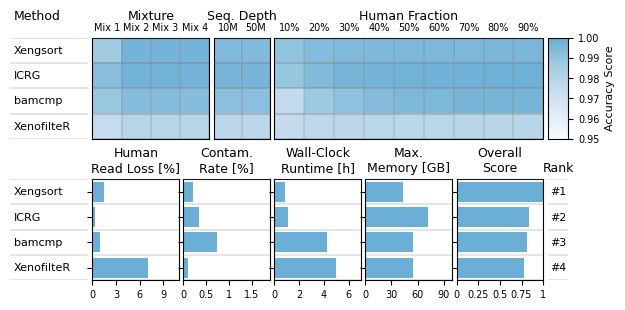

In [12]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

from matplotlib.colors import LinearSegmentedColormap
cmap_wb = LinearSegmentedColormap.from_list("white_blue", ["white", "#2171B5"])



def mm_to_inches(mm):
    return mm / 25.4

df = final_df.copy()
df["Avg_Human_Loss_pct"] = df["Avg_Human_Loss"] * 100
df["Avg_Contamination_Rate_pct"] = df["Avg_Contamination_Rate"] * 100

n = len(df)

mixture_cols = ["Mixture 1_Score", "Mixture 2_Score", "Mixture 3_Score", "Mixture 4_Score"]
depth_cols   = ["20000000_Score", "100000000_Score"]
mixavg_cols  = [f"{x}_Score" for x in ["0.1","0.2","0.3","0.4","0.5","0.6","0.7","0.8","0.9"]]

mixture_labels = {"Mixture 1_Score": "Mix 1", "Mixture 2_Score": "Mix 2",
                    "Mixture 3_Score": "Mix 3", "Mixture 4_Score": "Mix 4"}
depth_labels   = {"20000000_Score": "10M", "100000000_Score": "50M"}
mixavg_labels  = {f"{x}_Score": f"{int(float(x)*100)}%"
                    for x in ["0.1","0.2","0.3","0.4","0.5","0.6","0.7","0.8","0.9"]}

heat_cols = mixture_cols + depth_cols + mixavg_cols
vmin, vmax = 0.95, 1.0
row_y = np.arange(n)
Y_TITLE_R1 = 1.15
Y_TITLE_R2 = 1.05

df_reset = df.reset_index(drop=True)
highlight_idx = df_reset.index[df_reset["Method"].isin(["Xengsort", "bamcmp"])].tolist()
HIGHLIGHT_COLOR = "#D6EAF8"

fig = plt.figure(figsize=(mm_to_inches(183), mm_to_inches(80)))
gs = gridspec.GridSpec(
        2, 17, figure=fig,
        height_ratios=[1, 1], hspace=0.4, wspace=0.15,
        width_ratios=[3] + [1]*15 + [0.8]
    )


def add_title(ax, label, x=0.5, ha="center", y=None):
    if y is None:
        y = Y_TITLE_R1
    ax.text(x, y, label, transform=ax.transAxes,
            ha=ha, va="bottom", fontsize=9, clip_on=False)
        
def add_row_styling(ax, heatmap=False, fill=False):
    for y in np.arange(-0.5, n + 0.5, 1):
        ax.axhline(y, color="grey", linewidth=0.3, zorder=5)
    if fill:
        for idx in highlight_idx:
            ax.axhspan(idx - 0.5, idx + 0.5,
                    color=HIGHLIGHT_COLOR,
                        alpha=0.15 if heatmap else 0.4, zorder=0)
def hide_ax(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_facecolor("none")

    # ── ROW 1: Method column + Heatmaps + Colorbar ──────────────────
ax0 = fig.add_subplot(gs[0, 0])
ax0.set_xlim(0, 1); ax0.set_ylim(n - 0.5, -0.5)
hide_ax(ax0)
add_title(ax0, "Method", x=0.05, ha="left")
for i, row in df_reset.iterrows():
    ax0.text(0.05, i, row["Method"], fontsize=8, va="center", ha="left")
add_row_styling(ax0)

import matplotlib.colors as mcolors


blue = mcolors.to_rgb("#3A8EC4")
    #blue = mcolors.to_rgb("#4292C6")
    #blue = mcolors.to_rgb("#6BAED6")

from matplotlib.colors import LinearSegmentedColormap

blues_9 = ["#f7fbff", "#deebf7", "#c6dbef", "#9ecae1",
        "#6baed6",
           # "#4292c6",
             # "#2171b5",
             #"#08519c",
              # "#08306b"
            ]   # RColorBrewer::brewer.pal(9, "Blues")
            # append + rev(), matching your R pipe

from matplotlib.colors import LinearSegmentedColormap

cmap_wb = LinearSegmentedColormap.from_list("white_lightblue", ["white", "#9ecae1"], N=101)

    #cmap_wb = LinearSegmentedColormap.from_list("white_blue", ["white", blue])
cmap_wb = LinearSegmentedColormap.from_list("navy_blues", blues_9, N=101)




def heatmap_panel(gs_spec, cols, title, label_map):
    ax = fig.add_subplot(gs_spec)
    im = ax.imshow(df[cols].values, cmap=cmap_wb, vmin=vmin, vmax=vmax, aspect="auto")

    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([label_map[c] for c in cols],
                        rotation=0, ha="center", va="bottom", fontsize=7)
    ax.tick_params(axis="x", which="both", length=0)
    ax.set_yticks([])
    ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="grey", linewidth=0.3)
    ax.tick_params(which="minor", length=0)
    add_row_styling(ax, heatmap=True)
    add_title(ax, title)
    return ax, im

ax1, im = heatmap_panel(gs[0, 1:5],  mixture_cols, "Mixture",        mixture_labels)
ax2, _  = heatmap_panel(gs[0, 5:7],  depth_cols,   "Seq. Depth",     depth_labels)
ax3, _  = heatmap_panel(gs[0, 7:16], mixavg_cols,  "Human Fraction", mixavg_labels)

cbar_ax = fig.add_subplot(gs[0, 16])
cbar = fig.colorbar(im, cax=cbar_ax, orientation="vertical")
cbar.set_label("Accuracy Score", fontsize=8)
cbar.set_ticks(np.arange(vmin, vmax, 0.01))
cbar.set_ticklabels([f"{t:.2f}" for t in np.arange(vmin, vmax, 0.01)])
cbar.ax.tick_params(labelsize=7)

# ── ROW 2: Method labels + Bar panels + Rank ─────────────────────
ax_m = fig.add_subplot(gs[1, 0])
ax_m.set_xlim(0, 1); ax_m.set_ylim(n - 0.5, -0.5)
hide_ax(ax_m)
for i, row in df_reset.iterrows():
    ax_m.text(0.05, i, row["Method"], fontsize=8, va="center", ha="left")
add_row_styling(ax_m, fill=False)

from matplotlib.ticker import FuncFormatter

def bar_panel(gs_spec, col, title, color):
    ax = fig.add_subplot(gs_spec)
    ax.barh(row_y, df[col].values, color=color)
    ax.set_yticks(row_y); ax.set_yticklabels([])
    ax.set_ylim(n - 0.5, -0.5)
    ax.tick_params(axis="x", labelrotation=0, labelsize=7)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    add_row_styling(ax, fill=False)
    add_title(ax, title, y=Y_TITLE_R2)
    return ax

bar_color = blues_9[-1]
ax_hrl     = bar_panel(gs[1, 1:4],   "Avg_Human_Loss_pct",         "Human\nRead Loss [%]",    bar_color)
ax_hrl.set_xlim(0, 11)
ax_hrl.set_xticks([0, 3, 6, 9])

ax_contam  = bar_panel(gs[1, 4:7],   "Avg_Contamination_Rate_pct", "Contam.\nRate [%]",       bar_color)
ax_contam.set_xlim(0, 1.9)
ax_contam.set_xticks([0, 0.5, 1, 1.5])

ax_runtime = bar_panel(gs[1, 7:10],  "Realtime_h",                 "Wall-Clock\nRuntime [h]", bar_color)
ax_runtime.set_xlim(0, 7)
ax_runtime.set_xticks([0, 2, 4, 6])

ax_memory  = bar_panel(gs[1, 10:13], "Max_memory_gb",              "Max.\nMemory [GB]",       bar_color)
ax_memory.set_xlim(0, 100)
ax_memory.set_xticks([0, 30, 60, 90])

ax_score   = bar_panel(gs[1, 13:16], "Score",                      "Overall\nScore",          bar_color)
ax_score.set_xlim(0, 1)
ax_score.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax_rank = fig.add_subplot(gs[1, 16])
ax_rank.set_xlim(0, 1); ax_rank.set_ylim(n - 0.5, -0.5)
hide_ax(ax_rank)
for i, rank in zip(row_y, df["Ranking"]):
    ax_rank.text(0.5, i, f"#{int(rank)}", ha="center", va="center",
                fontsize=8)
add_row_styling(ax_rank, fill=False)
add_title(ax_rank, "Rank", y=Y_TITLE_R2)

plt.savefig(fig_dir / "summary_figure.pdf", bbox_inches="tight", dpi=300)
plt.savefig(fig_dir / "summary_figure.png", bbox_inches="tight", dpi=300)


In [13]:
df.to_csv(data_dir / "benchmark_figure_data.csv")

### Individual plots

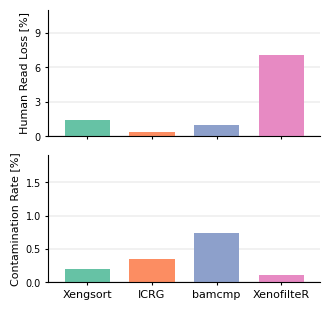

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def mm_to_inches(mm):
    return mm / 25.4

# ── Colors: Set2 in the requested order ──────────────────────────
METHOD_ORDER = ["Xengsort", "ICRG", "bamcmp", "XenofilteR"]
set2 = plt.get_cmap("Set2").colors
method_colors = {m: set2[i] for i, m in enumerate(METHOD_ORDER)}

# ── Data, ordered ────────────────────────────────────────────────
d = final_df.copy()
d["Avg_Human_Loss_pct"] = d["Avg_Human_Loss"] * 100
d["Avg_Contamination_Rate_pct"] = d["Avg_Contamination_Rate"] * 100

d["Method"] = pd.Categorical(d["Method"], categories=METHOD_ORDER, ordered=True)
d = d.sort_values("Method").dropna(subset=["Method"]).reset_index(drop=True)

x = np.arange(len(d))
colors = [method_colors[m] for m in d["Method"]]

# ── Figure ───────────────────────────────────────────────────────
fig, (ax_hrl, ax_con) = plt.subplots(
    2, 1, sharex=True,
    figsize=(mm_to_inches(89), mm_to_inches(90)),
    gridspec_kw={"hspace": 0.15},
)

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=7, length=2)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color="grey", linewidth=0.3, alpha=0.5)

ax_hrl.bar(x, d["Avg_Human_Loss_pct"], color=colors, width=0.7)
ax_hrl.set_ylabel("Human Read Loss [%]", fontsize=8)
ax_hrl.set_ylim(0, 11)
ax_hrl.set_yticks([0, 3, 6, 9])
style(ax_hrl)

ax_con.bar(x, d["Avg_Contamination_Rate_pct"], color=colors, width=0.7)
ax_con.set_ylabel("Contamination Rate [%]", fontsize=8)
ax_con.set_ylim(0, 1.9)
ax_con.set_yticks([0, 0.5, 1, 1.5])
style(ax_con)

ax_con.set_xticks(x)
ax_con.set_xticklabels(d["Method"], fontsize=8)
ax_con.set_xlim(-0.6, len(d) - 0.4)

fig.savefig(fig_dir / "panel_loss_contamination.pdf", bbox_inches="tight", dpi=300)
fig.savefig(fig_dir / "panel_loss_contamination.png", bbox_inches="tight", dpi=300)

In [15]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import pandas as pd
import numpy as np

def mm_to_inches(mm):
    return mm / 25.4

METHOD_ORDER = ["Xengsort", "ICRG", "bamcmp", "XenofilteR"]
set2 = plt.get_cmap("Set2").colors
method_colors = {m: set2[i] for i, m in enumerate(METHOD_ORDER)}

d = final_df.copy()
d["Avg_Human_Loss_pct"] = d["Avg_Human_Loss"] * 100
d["Avg_Contamination_Rate_pct"] = d["Avg_Contamination_Rate"] * 100
d["Method"] = pd.Categorical(d["Method"], categories=METHOD_ORDER, ordered=True)
d = d.sort_values("Method").dropna(subset=["Method"]).reset_index(drop=True)

x = np.arange(len(d))
colors = [method_colors[m] for m in d["Method"]]
legend_handles = [Patch(facecolor=method_colors[m], label=m) for m in METHOD_ORDER]

def style_bar_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=7, length=2)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color="grey", linewidth=0.3, alpha=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.set_xlim(-0.6, len(d) - 0.4)

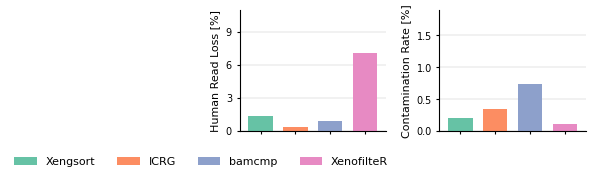

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(mm_to_inches(103), mm_to_inches(40)))

specs = [
    ("Avg_Human_Loss_pct",         "Human Read Loss [%]",   (0, 11),  [0, 3, 6, 9]),
    ("Avg_Contamination_Rate_pct", "Contamination Rate [%]", (0, 1.9), [0, 0.5, 1, 1.5]),
]

for ax, (col, ylab, ylim, yticks) in zip(axes, specs):
    ax.bar(x, d[col], color=colors, width=0.7)
    ax.set_ylabel(ylab, fontsize=8)
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    style_bar_ax(ax)

fig.legend(handles=legend_handles, loc="center right", ncol=4,
           frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(fig_dir / "panel_loss_contamination.pdf", bbox_inches="tight", dpi=300)
fig.savefig(fig_dir / "panel_loss_contamination.png", bbox_inches="tight", dpi=300)

add standard deviation


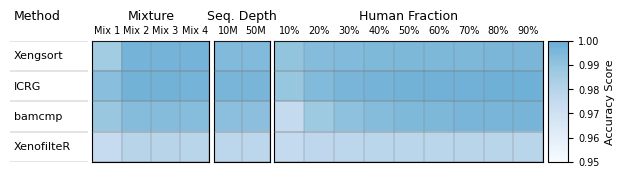

In [17]:
blues_9 = ["#f7fbff", "#deebf7", "#c6dbef", "#9ecae1", "#6baed6"]
cmap_wb = LinearSegmentedColormap.from_list("navy_blues", blues_9, N=101)

mixture_cols = ["Mixture 1_Score", "Mixture 2_Score", "Mixture 3_Score", "Mixture 4_Score"]
depth_cols   = ["20000000_Score", "100000000_Score"]
mixavg_cols  = [f"{v}_Score" for v in ["0.1","0.2","0.3","0.4","0.5","0.6","0.7","0.8","0.9"]]

mixture_labels = {c: f"Mix {i+1}" for i, c in enumerate(mixture_cols)}
depth_labels   = {"20000000_Score": "10M", "100000000_Score": "50M"}
mixavg_labels  = {f"{v}_Score": f"{int(float(v)*100)}%"
                  for v in ["0.1","0.2","0.3","0.4","0.5","0.6","0.7","0.8","0.9"]}

n = len(d)
vmin, vmax = 0.95, 1.0

fig = plt.figure(figsize=(mm_to_inches(183), mm_to_inches(40)))
gs = gridspec.GridSpec(1, 17, figure=fig, wspace=0.15,
                       width_ratios=[3] + [1]*15 + [0.8])

def hide_ax(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_facecolor("none")

def add_title(ax, label, x=0.5, ha="center", y=1.15):
    ax.text(x, y, label, transform=ax.transAxes, ha=ha, va="bottom",
            fontsize=9, clip_on=False)

def add_rowlines(ax):
    for yy in np.arange(-0.5, n + 0.5, 1):
        ax.axhline(yy, color="grey", linewidth=0.3, zorder=5)

ax0 = fig.add_subplot(gs[0, 0])
ax0.set_xlim(0, 1); ax0.set_ylim(n - 0.5, -0.5)
hide_ax(ax0)
add_title(ax0, "Method", x=0.05, ha="left")
for i, m in enumerate(d["Method"]):
    ax0.text(0.05, i, m, fontsize=8, va="center", ha="left")
add_rowlines(ax0)

def heatmap_panel(gs_spec, cols, title, label_map):
    ax = fig.add_subplot(gs_spec)
    im = ax.imshow(d[cols].values, cmap=cmap_wb, vmin=vmin, vmax=vmax, aspect="auto")
    ax.xaxis.set_ticks_position("top")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([label_map[c] for c in cols], ha="center", va="bottom", fontsize=7)
    ax.tick_params(axis="x", which="both", length=0)
    ax.set_yticks([])
    ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="grey", linewidth=0.3)
    ax.tick_params(which="minor", length=0)
    add_rowlines(ax)
    add_title(ax, title)
    return ax, im

_, im = heatmap_panel(gs[0, 1:5],  mixture_cols, "Mixture",        mixture_labels)
heatmap_panel(gs[0, 5:7],  depth_cols,  "Seq. Depth",     depth_labels)
heatmap_panel(gs[0, 7:16], mixavg_cols, "Human Fraction", mixavg_labels)

cbar = fig.colorbar(im, cax=fig.add_subplot(gs[0, 16]), orientation="vertical")
cbar.set_label("Accuracy Score", fontsize=8)
cbar.set_ticks(np.arange(vmin, vmax, 0.01))
cbar.set_ticklabels([f"{t:.2f}" for t in np.arange(vmin, vmax, 0.01)])
cbar.ax.tick_params(labelsize=7)

fig.savefig(fig_dir / "panel_accuracy_heatmaps.pdf", bbox_inches="tight", dpi=300)
fig.savefig(fig_dir / "panel_accuracy_heatmaps.png", bbox_inches="tight", dpi=300)

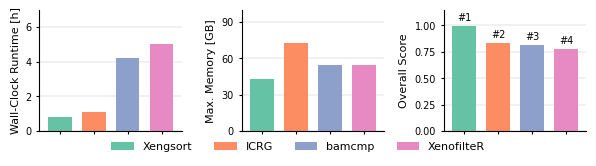

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(mm_to_inches(154), mm_to_inches(40)))

specs = [
    ("Realtime_h",     "Wall-Clock Runtime [h]", (0, 7),   [0, 2, 4, 6]),
    ("Max_memory_gb",  "Max. Memory [GB]",       (0, 100), [0, 30, 60, 90]),
    ("Score",          "Overall Score",          (0, 1.15),[0, 0.25, 0.5, 0.75, 1]),
]

for ax, (col, ylab, ylim, yticks) in zip(axes, specs):
    ax.bar(x, d[col], color=colors, width=0.7)
    ax.set_ylabel(ylab, fontsize=8)
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    style_bar_ax(ax)

for xi, val, rank in zip(x, d["Score"], d["Ranking"]):
    axes[2].text(xi, val + 0.03, f"#{int(rank)}", ha="center", va="bottom", fontsize=7)

fig.legend(handles=legend_handles, loc="lower center", ncol=4,
           frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(fig_dir / "panel_runtime_memory_score.pdf", bbox_inches="tight", dpi=300)
fig.savefig(fig_dir / "panel_runtime_memory_score.png", bbox_inches="tight", dpi=300)

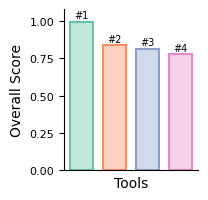

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

bar_alpha = 0.4
bar_lw = 1.5

methods = df_reset["Method"].tolist()
colors = dict(zip(methods, sns.color_palette("Set2", len(methods))))

fig, ax = plt.subplots(figsize=(mm_to_inches(50), mm_to_inches(50)))

xpos = np.arange(len(methods))
bars = ax.bar(xpos, df_reset["Score"].values,
              color=[colors[m] for m in methods], width=0.7)

for p in bars:
    r, g, b = p.get_facecolor()[:3]
    p.set_edgecolor((r, g, b, 1))
    p.set_facecolor((r, g, b, bar_alpha))
    p.set_linewidth(bar_lw)

for xi, score, rank in zip(xpos, df_reset["Score"].values, df_reset["Ranking"]):
    ax.text(xi, score + 0.01, f"#{int(rank)}",
            ha="center", va="bottom", fontsize=7)

ax.set_ylabel("Overall Score", fontsize=10)
ax.set_xlabel("Tools", fontsize=10)
ax.set_xticks([])
ax.set_ylim(0, 1.08)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.tick_params(axis="y", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)

fig.subplots_adjust(left=0.3, bottom=0.15, right=0.98, top=0.97)

fig.savefig(fig_dir / "barplot_overall_score.pdf", dpi=300, pad_inches=0)

In [4]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import mm_to_inches

# Load
alignment_rates = pd.read_table(Path.cwd() / "results" / "samtools_alignment_plot.txt")

# Parse percentage and replicate: "..._50000000_10p_0_GRCh38" -> 10, Rep1
parts = alignment_rates["Sample"].str.extract(r"_([\d.]+)p_(\d+)_")
pct = parts[0].astype(float)
rep = parts[1].astype(int) + 1  # replicate 0 -> Rep1

# Keep only the first replicate, label as "10%", "20%", ...
alignment_rates = (
    alignment_rates
    .assign(pct=pct, rep=rep, Sample=parts[0] + "%")
    .query("rep == 1")
    .sort_values("pct")
    .drop(columns=["pct", "rep"])
    .set_index("Sample")
)

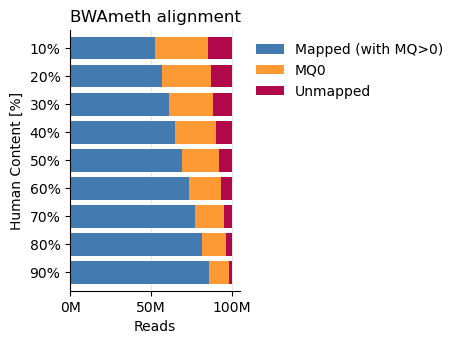

In [6]:
# MultiQC samtools colours, in column order: mapped (MQ>0), MQ0, unmapped
multiqc_colors = ["#437bb1", "#FF9933", "#b1084c"]

# Plot
fig, ax = plt.subplots(figsize=(120 / 25.4, 90 / 25.4), facecolor="white")
ax.set_facecolor("white")

alignment_rates.plot(
    kind="barh",
    stacked=True,
    width=0.8,
    color=multiqc_colors[: alignment_rates.shape[1]],
    edgecolor="none",
    ax=ax,
)

ax.invert_yaxis()  # lowest percentage at the top
ax.set_xlabel("Reads")
ax.set_ylabel("Human Content [%]")
ax.set_title("BWAmeth alignment")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)

from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:g}M"))
ax.set_xlabel("Reads")
# Clean look: light vertical gridlines, no top/right spines
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig(
    fig_dir / "samtools_alignment_plot.pdf",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()